# VAE on MNIST

1. Train a convolutional VAE and look at its reconstructions and latent space.
2. Train the same CNN classifier on original images (**Baseline**) and on VAE reconstructions (**Reconstructed**),
   plus a third classifier on the VAE latents μ (**Latent**).
3. Add Gaussian noise to the test set and check how much the VAE removes.

## Colab setup
Use a GPU runtime (Runtime → Change runtime type → T4 GPU). torch/torchvision come preinstalled.

In [1]:
!pip install -q umap-learn

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import umap
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from torchvision.utils import make_grid

## Config

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
torch.manual_seed(0)

batch_size = 128
lr = 1e-3
z_dim = 16
beta = 1.0  # weight of the KL term
vae_epochs = 20
clf_epochs = 5
sigmas = [0, 0.1, 0.2, 0.3]

cuda


## Data
MNIST as plain tensors in [0, 1], kept on the GPU. No normalization: the decoder ends with a sigmoid
and the noisy images get clamped to [0, 1].

In [4]:
def load(train):
    ds = datasets.MNIST('data', train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1).to(device), ds.targets.to(device)


x_train, y_train = load(True)
x_test, y_test = load(False)
print(x_train.shape, x_test.shape)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.64MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.13MB/s]


torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## Models

In [5]:
class VAE(nn.Module):
    def __init__(self, z_dim):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1), nn.ReLU(),   # 28 -> 14
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),  # 14 -> 7
            nn.Flatten())
        self.mu = nn.Linear(64 * 7 * 7, z_dim)
        self.logvar = nn.Linear(64 * 7 * 7, z_dim)
        self.dec = nn.Sequential(
            nn.Linear(z_dim, 64 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # 7 -> 14
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1), nn.Sigmoid())  # 14 -> 28

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)  # reparameterization trick
        return self.dec(z), mu, logvar


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)


def make_latent_mlp():
    return nn.Sequential(nn.Linear(z_dim, 64), nn.ReLU(), nn.Linear(64, 10)).to(device)

## 1. Train the VAE
Loss = BCE reconstruction (summed over pixels) + β · KL(q(z|x) ‖ N(0, I)), both averaged over the batch.

In [6]:
vae = VAE(z_dim).to(device)
opt = torch.optim.Adam(vae.parameters(), lr=lr)
loader = DataLoader(TensorDataset(x_train), batch_size=batch_size, shuffle=True)

history = {'recon': [], 'kl': []}
for epoch in range(1, vae_epochs + 1):
    recon_sum, kl_sum = 0.0, 0.0
    for (x,) in loader:
        x_hat, mu, logvar = vae(x)
        recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / len(x)
        kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / len(x)
        loss = recon + beta * kl

        opt.zero_grad()
        loss.backward()
        opt.step()
        recon_sum += recon.item()
        kl_sum += kl.item()

    history['recon'].append(recon_sum / len(loader))
    history['kl'].append(kl_sum / len(loader))
    print(f"[{epoch}/{vae_epochs}] recon: {history['recon'][-1]:.2f}, kl: {history['kl'][-1]:.2f}")

vae.eval()

[1/20] recon: 150.35, kl: 16.96
[2/20] recon: 90.44, kl: 23.14
[3/20] recon: 85.26, kl: 23.61
[4/20] recon: 82.76, kl: 23.86
[5/20] recon: 81.22, kl: 24.01
[6/20] recon: 80.09, kl: 24.12
[7/20] recon: 79.27, kl: 24.20
[8/20] recon: 78.59, kl: 24.26
[9/20] recon: 78.06, kl: 24.26
[10/20] recon: 77.59, kl: 24.26
[11/20] recon: 77.21, kl: 24.28
[12/20] recon: 76.86, kl: 24.32
[13/20] recon: 76.59, kl: 24.28
[14/20] recon: 76.30, kl: 24.28
[15/20] recon: 76.08, kl: 24.25
[16/20] recon: 75.89, kl: 24.24
[17/20] recon: 75.68, kl: 24.22
[18/20] recon: 75.51, kl: 24.19
[19/20] recon: 75.38, kl: 24.17
[20/20] recon: 75.21, kl: 24.16


VAE(
  (enc): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (mu): Linear(in_features=3136, out_features=16, bias=True)
  (logvar): Linear(in_features=3136, out_features=16, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=16, out_features=3136, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): Sigmoid()
  )
)

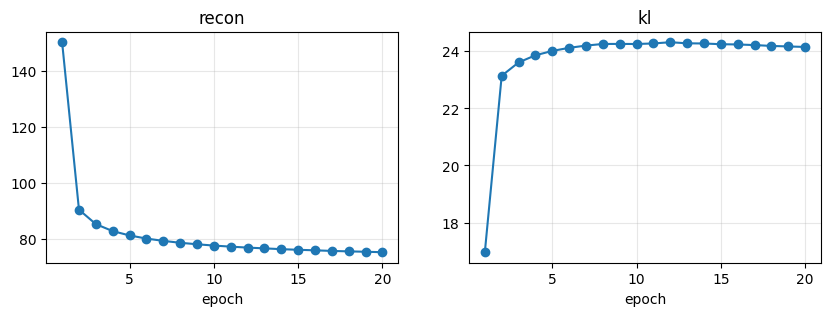

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (name, values) in zip(axes, history.items()):
    ax.plot(range(1, vae_epochs + 1), values, marker='o')
    ax.set_title(name)
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
plt.show()

### Helpers
Deterministic encode / reconstruct: use μ, no sampling. Done in chunks to keep GPU memory low.

In [8]:
@torch.no_grad()
def encode(x):
    return torch.cat([vae.encode(chunk)[0] for chunk in x.split(1000)])


@torch.no_grad()
def reconstruct(x):
    return torch.cat([vae.dec(vae.encode(chunk)[0]) for chunk in x.split(1000)])


def show(rows, titles):
    # rows: list of (n, 1, 28, 28) tensors, shown one under another
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, 1.2 * len(rows)))
    for ax, row, title in zip(axes, rows, titles):
        ax.imshow(make_grid(row.cpu(), nrow=len(row), pad_value=1).permute(1, 2, 0))
        ax.set_title(title, loc='left', fontsize=10)
        ax.axis('off')
    plt.show()

### Original vs reconstructed

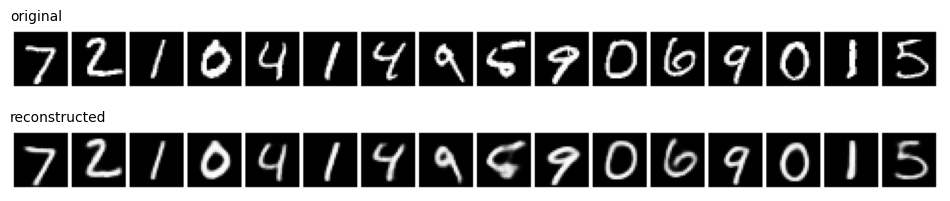

In [9]:
show([x_test[:16], reconstruct(x_test[:16])], ['original', 'reconstructed'])

### Latent space (UMAP of test μ)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


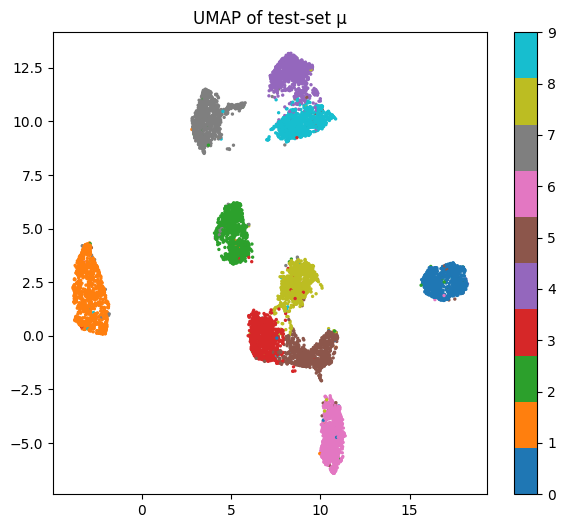

In [10]:
mu_test = encode(x_test)
reducer = umap.UMAP(random_state=0)
emb = reducer.fit_transform(mu_test.cpu().numpy())

plt.figure(figsize=(7, 6))
plt.scatter(emb[:, 0], emb[:, 1], c=y_test.cpu(), cmap='tab10', s=2)
plt.colorbar(ticks=range(10))
plt.title('UMAP of test-set μ')
plt.show()

### Interpolation between digit means
Take the mean μ of each digit class, then 4 evenly spaced points on the straight line between the means of
d and d + 1 in the 16-dim latent space. Each point is decoded into an image and placed on the UMAP with
`reducer.transform`. The path is straight in latent space but bends in 2D, because UMAP is non-linear.
Stars mark the class means and dots the 4 intermediate points.

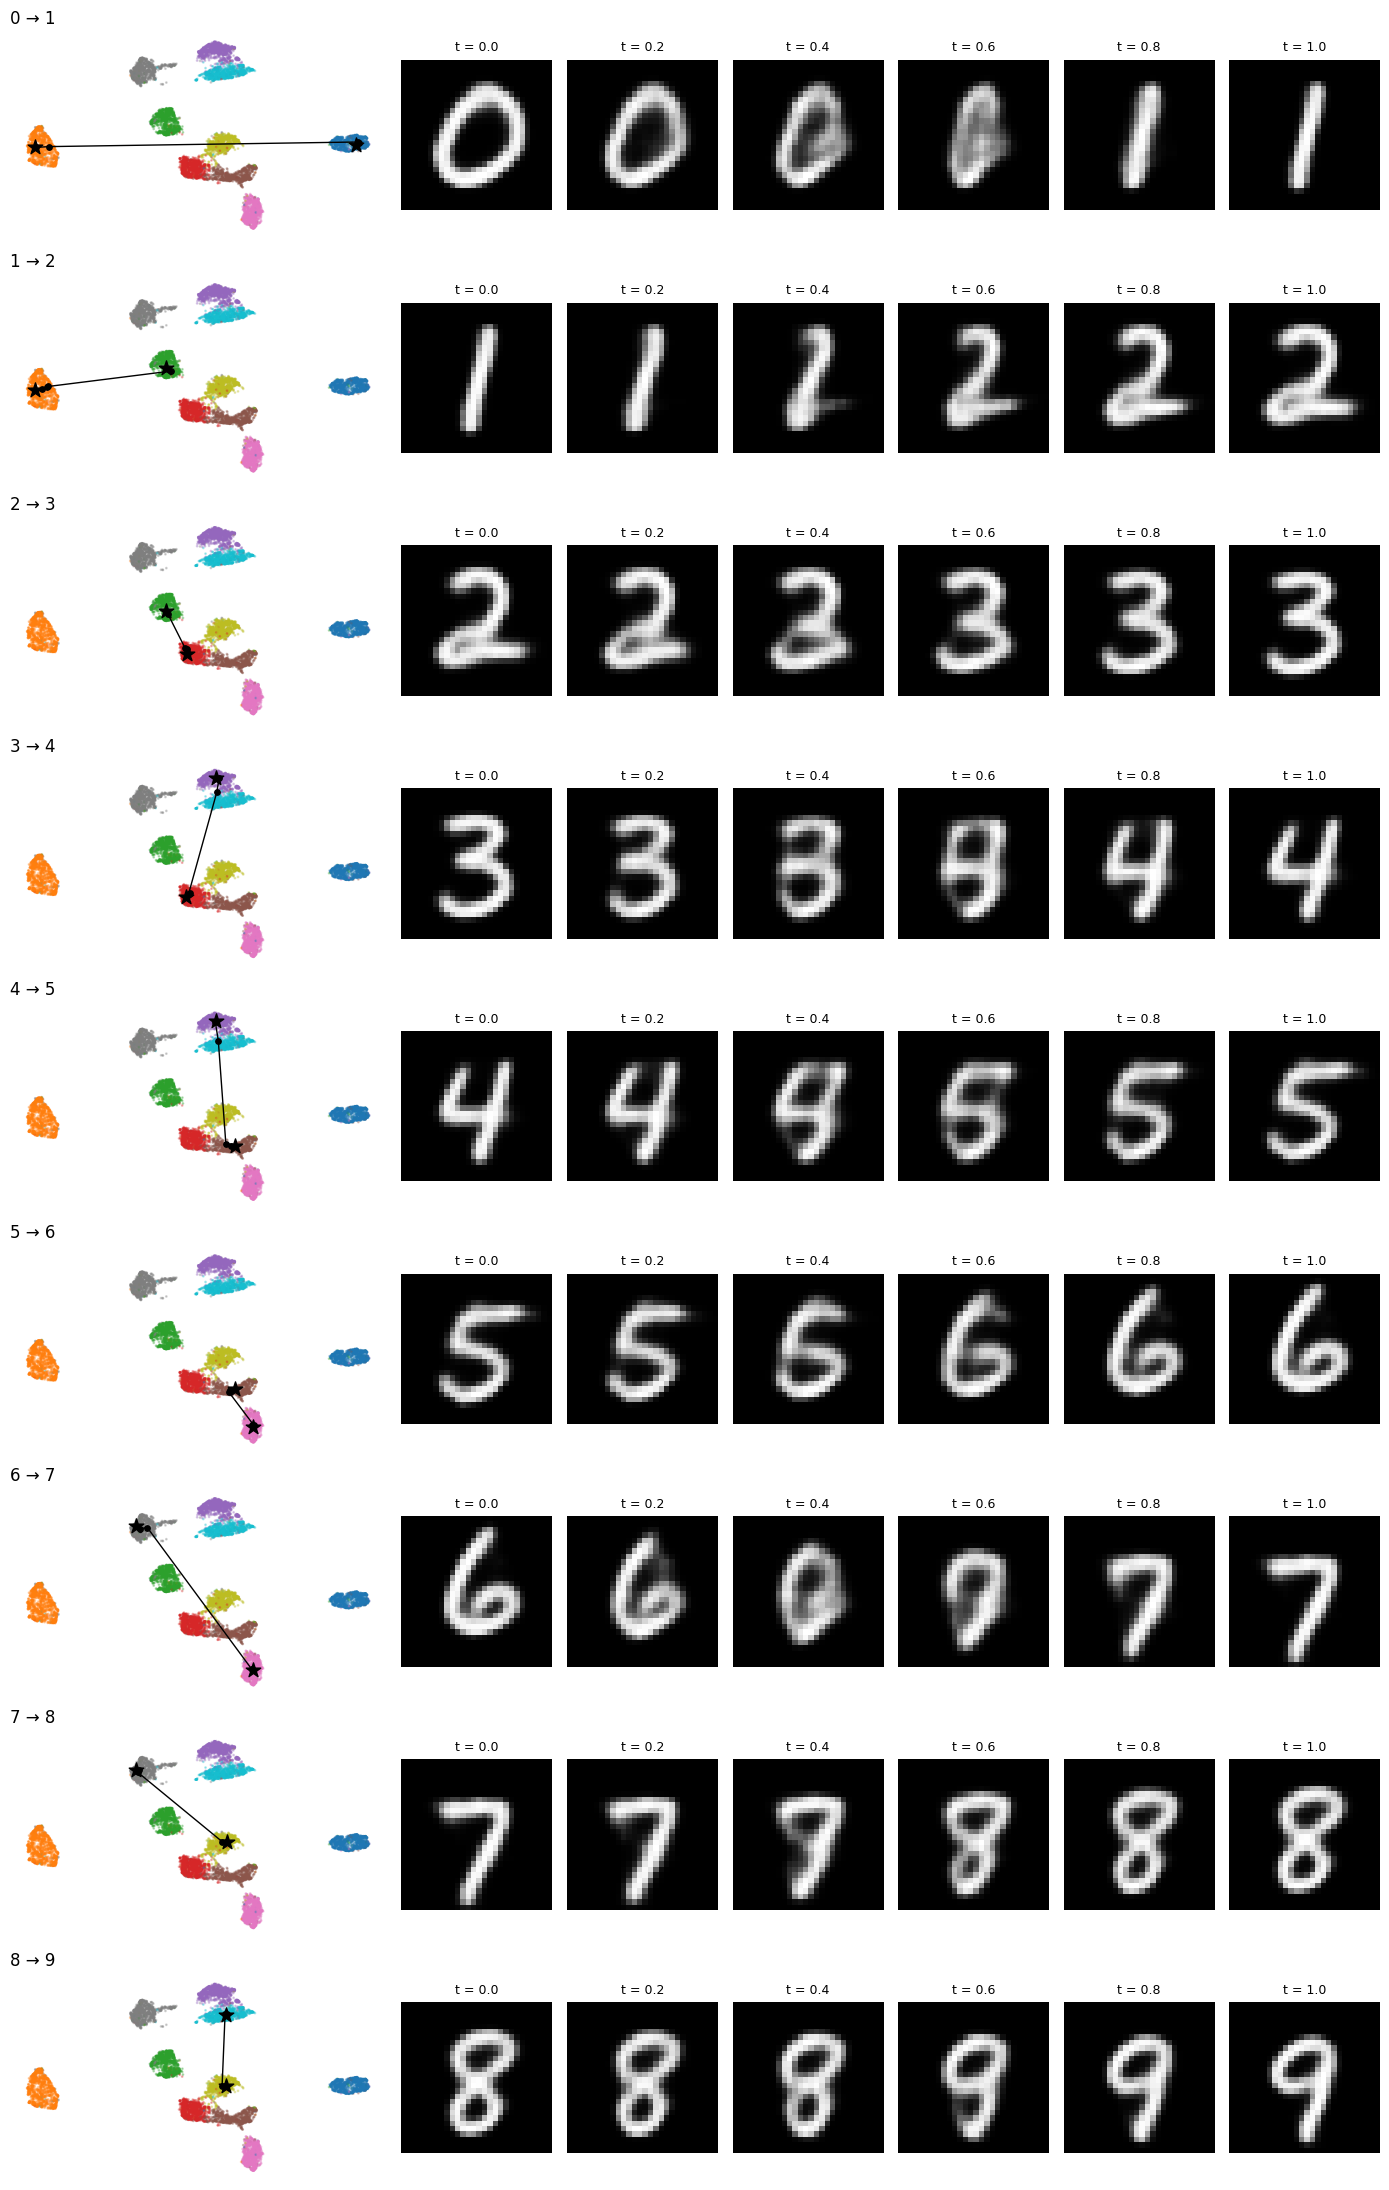

In [11]:
means = torch.stack([mu_test[y_test == d].mean(0) for d in range(10)])
t = torch.linspace(0, 1, 6, device=device)[:, None]  # mean, 4 points, mean

fig, axes = plt.subplots(9, 7, figsize=(14, 22), gridspec_kw={'width_ratios': [2.5] + [1] * 6})
for d in range(9):
    z = (1 - t) * means[d] + t * means[d + 1]
    with torch.no_grad():
        imgs = vae.dec(z).cpu()
    path = reducer.transform(z.cpu().numpy())

    ax = axes[d, 0]
    ax.scatter(emb[:, 0], emb[:, 1], c=y_test.cpu(), cmap='tab10', s=1, alpha=0.3)
    ax.plot(path[:, 0], path[:, 1], 'k-', lw=1)
    ax.scatter(path[1:-1, 0], path[1:-1, 1], c='k', s=15, zorder=3)
    ax.scatter(path[[0, -1], 0], path[[0, -1], 1], c='k', marker='*', s=120, zorder=3)
    ax.set_title(f'{d} → {d + 1}', loc='left')
    ax.axis('off')

    for ax, img, ti in zip(axes[d, 1:], imgs, t.flatten().tolist()):
        ax.imshow(img[0], cmap='gray')
        ax.set_title(f't = {ti:.1f}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Analysis
- Which features survive reconstruction (overall shape, stroke direction, digit identity)?
- Which are lost (thin strokes, sharp edges, small gaps or loops, unusual writing styles)?
- Are any digits reconstructed as a *different* digit? Do those cases sit between clusters in the UMAP?

**Training.** The reconstruction loss falls from 150 to 75 over 20 epochs. KL rises to ~24 in the first
epochs and then stays flat, so the latent code carries information (no posterior collapse).

**What survives.** The digit's identity, overall shape, slant, stroke thickness and position are preserved.
All 16 shown digits are still recognisable as the same class.

**What is lost.** High-frequency detail: edges are blurred and fine strokes fade (thin parts of the 2 and 4).
Atypical writing gets pulled toward a "typical" digit: the 5 at index 8 turns into a blob, and the
hooked 9 at index 7 loses its shape. With 16 numbers per image and a KL penalty, the VAE keeps
what is common across the dataset and drops what is individual.

**Latent space.** 0, 1, 2, 6 and 7 form clean, separate clusters. 3/5/8 touch, and so do 4/9, which are the
classic MNIST confusions. These are the regions where a reconstruction can drift to a neighbouring class.

## 2. Classifiers
Three models, all trained with the same loop:
- **Baseline**: CNN on original images
- **Reconstructed**: same CNN on Decoder(Encoder(I))
- **Latent**: small MLP on μ = Encoder(I), with the VAE frozen

In [12]:
def train_classifier(model, X, y, epochs):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
        print(f'  [{epoch}/{epochs}] loss: {loss.item():.4f}')
    model.eval()
    return model


@torch.no_grad()
def accuracy(model, X, y):
    preds = torch.cat([model(chunk).argmax(1) for chunk in X.split(1000)])
    return (preds == y).float().mean().item()

In [13]:
x_train_rec = reconstruct(x_train)
mu_train = encode(x_train)

print('Baseline')
clf_base = train_classifier(make_cnn(), x_train, y_train, clf_epochs)
print('Reconstructed')
clf_rec = train_classifier(make_cnn(), x_train_rec, y_train, clf_epochs)
print('Latent')
clf_lat = train_classifier(make_latent_mlp(), mu_train, y_train, clf_epochs)

Baseline
  [1/5] loss: 0.0729
  [2/5] loss: 0.0762
  [3/5] loss: 0.1030
  [4/5] loss: 0.0313
  [5/5] loss: 0.0816
Reconstructed
  [1/5] loss: 0.1591
  [2/5] loss: 0.1274
  [3/5] loss: 0.1402
  [4/5] loss: 0.0763
  [5/5] loss: 0.0334
Latent
  [1/5] loss: 0.4185
  [2/5] loss: 0.1409
  [3/5] loss: 0.1561
  [4/5] loss: 0.1195
  [5/5] loss: 0.1001


In [14]:
pd.Series({
    'Baseline': accuracy(clf_base, x_test, y_test),
    'Reconstructed': accuracy(clf_rec, x_test, y_test),
    'Latent': accuracy(clf_lat, mu_test, y_test),
}, name='accuracy on original test set')

,accuracy on original test set
Baseline,0.9867
Reconstructed,0.9762
Latent,0.9655


### Analysis
- How much accuracy does Reconstructed lose compared to Baseline? What does that say about the information
  the VAE throws away?
- How does a 16-dim latent compare to the full 784-pixel image as classifier input?

| Classifier | Test accuracy |
|---|---|
| Baseline (original images) | 98.68% |
| Reconstructed (VAE outputs) | 97.72% |
| Latent (μ, 16 dims) | 96.57% |

Training on reconstructions costs about 1 point. The reconstructions keep enough class information to
learn from, but the blurred strokes and the "typical-ised" odd digits remove some cues the Baseline uses.
The Reconstructed classifier also sees slightly different inputs at test time (sharp originals vs the
blurry images it was trained on), and it still generalises well.

The Latent classifier gets 96.6% from just 16 numbers, 49× fewer than the 784 pixels. The VAE was trained
without labels, yet its latent space already separates the classes well, as the UMAP plot shows.
The remaining errors come from the overlapping 3/5/8 and 4/9 regions.

## 3. Input noise
For each σ: `noisy = clamp(I + N(0, σ²), 0, 1)` and `denoised = Decoder(Encoder(noisy))`.
Baseline and Reconstructed are tested on both sets; Latent is tested on Encoder(noisy).
σ = 0 is the clean reference row.

In [15]:
torch.manual_seed(0)
rows, examples = [], []
for sigma in sigmas:
    noisy = (x_test + sigma * torch.randn_like(x_test)).clamp(0, 1)
    denoised = reconstruct(noisy)
    rows.append({
        'sigma': sigma,
        'Baseline / noisy': accuracy(clf_base, noisy, y_test),
        'Baseline / denoised': accuracy(clf_base, denoised, y_test),
        'Reconstructed / noisy': accuracy(clf_rec, noisy, y_test),
        'Reconstructed / denoised': accuracy(clf_rec, denoised, y_test),
        'Latent / Encoder(noisy)': accuracy(clf_lat, encode(noisy), y_test),
    })
    examples.append((sigma, noisy[:12], denoised[:12]))

results = pd.DataFrame(rows).set_index('sigma')
results

,Baseline / noisy,Baseline / denoised,Reconstructed / noisy,Reconstructed / denoised,Latent / Encoder(noisy)
sigma,,,,,
0.0,0.9867,0.9691,0.9762,0.9728,0.9655
0.1,0.9837,0.9082,0.9751,0.9141,0.8723
0.2,0.9753,0.4687,0.9651,0.4708,0.4187
0.3,0.9467,0.2968,0.9314,0.2873,0.2475


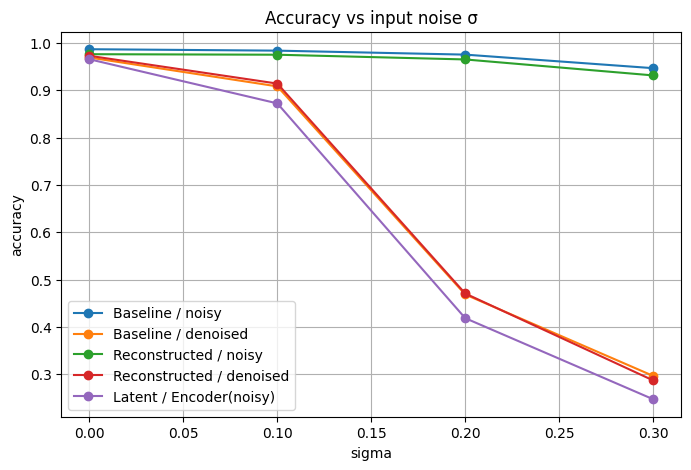

In [16]:
results.plot(marker='o', figsize=(8, 5), grid=True, ylabel='accuracy', title='Accuracy vs input noise σ')
plt.show()

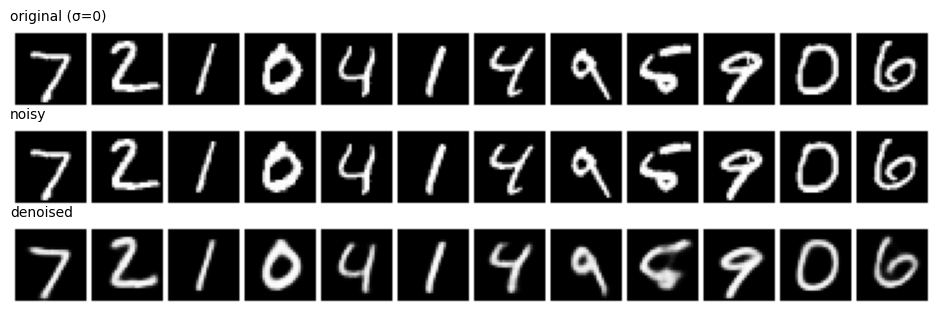

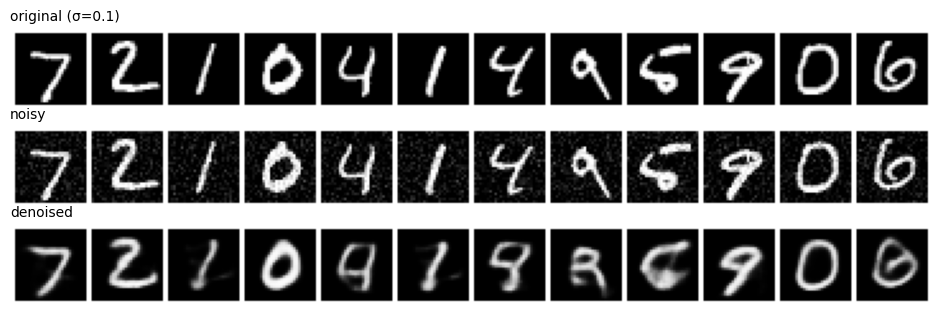

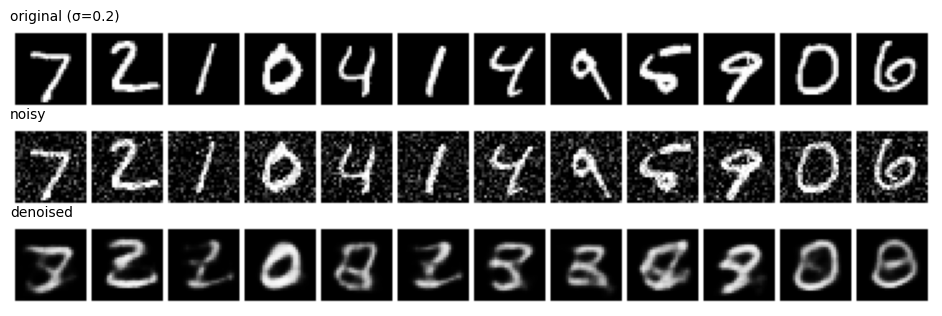

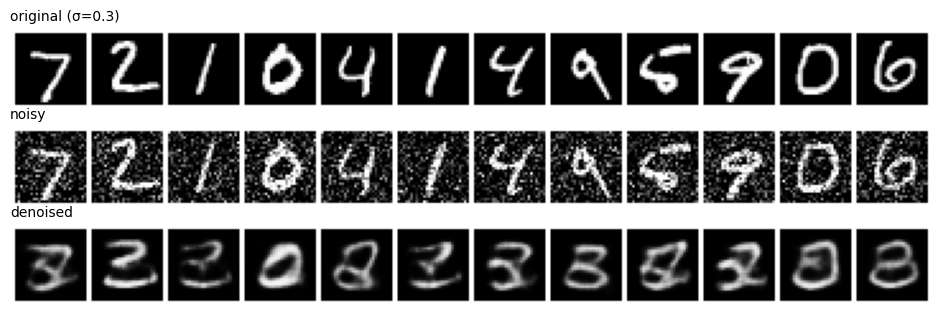

In [17]:
for sigma, noisy, denoised in examples:
    show([x_test[:12], noisy, denoised], [f'original (σ={sigma})', 'noisy', 'denoised'])

### Analysis
- Does the VAE remove the noise? Compare the noisy and denoised accuracies for Baseline as σ grows.
- Is Reconstructed more robust on noisy inputs than Baseline? Why might it be?
- How does the Latent classifier degrade compared to the image classifiers?
- At which σ does the VAE start reconstructing the wrong digit?

| σ | Baseline / noisy | Baseline / denoised | Reconstructed / noisy | Reconstructed / denoised | Latent |
|---|---|---|---|---|---|
| 0 | 98.7 | 96.9 | 97.7 | 97.2 | 96.6 |
| 0.1 | 98.4 | 91.8 | 97.7 | 92.1 | 87.9 |
| 0.2 | 97.5 | 49.2 | 96.8 | 49.2 | 45.7 |
| 0.3 | 94.7 | 30.6 | 94.0 | 28.8 | 25.6 |

**The VAE does not denoise. It makes things worse.** Both CNNs are robust to the noise on its own
(still ~94% at σ = 0.3). Passing the noisy image through the VAE first drops accuracy to 92% at σ = 0.1,
49% at σ = 0.2 and ~30% at σ = 0.3. In the example grids, the "denoised" images are clean, but they are
often the *wrong digit*. From σ = 0.2 most inputs come out as the same blurry 8/3-like shape,
whatever the original digit was.

**Why.** Clamping to [0, 1] makes the noise one-sided on the black background (~80% of the pixels):
a background pixel becomes max(0, N(0, σ²)), with mean σ/√(2π) ≈ 0.04 / 0.08 / 0.12. To the encoder,
the image becomes globally brighter with thousands of active pixels, which it never saw during training.
That input is off the training distribution, and the encoder maps it to a generic region of the latent
space that decodes to a "mean digit". The Latent column confirms the encoder is the problem:
classifying μ(noisy) directly fails just as badly (25.6% at σ = 0.3), so the decoder is not to blame.

**Baseline vs Reconstructed.** On the raw noisy images the two behave almost the same; Baseline is even
slightly better. Training on smooth reconstructions does not make the classifier noise-robust.
On the denoised images the two are also equal, since by then the VAE has already decided which digit it is.

**Conclusion.** A VAE trained only on clean images does not learn to remove noise. It keeps outputs on the
clean-digit manifold, but it projects noisy inputs onto the *wrong place* on that manifold. The clean
outputs look convincing but carry the wrong label, which is worse than leaving the noise in. Actual
denoising needs noise during training: feed I + N to the encoder and reconstruct the clean I
(a denoising VAE).